In [7]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import joblib

In [3]:
# Step 2: Load the dataset
# Source: Kaggle - Telco Customer Churn (blastchar)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Step 3: Perform basic data exploration
print(df.shape)
df.info()
print(df.describe())
print(df['Churn'].value_counts())
print(df.isnull().sum())

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [5]:
# Step 4: Handle missing values
# TotalCharges has blank strings, so convert to numeric first
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].isnull().sum())

# Fill missing values with the median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Drop the ID column (not useful for prediction)
df = df.drop('customerID', axis=1)

11


In [8]:
# Step 5: Encode categorical variables
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [9]:
# Step 6: Split features (X) and target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Step 7: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [10]:
# Step 8: Apply the Random Forest model
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Step 9: Train the model
rf.fit(X_train, y_train)

# Step 10: Make predictions
y_pred = rf.predict(X_test)

Accuracy : 0.7920511000709723
Precision: 0.6372881355932203
Recall   : 0.5026737967914439
F1-Score : 0.5620328849028401


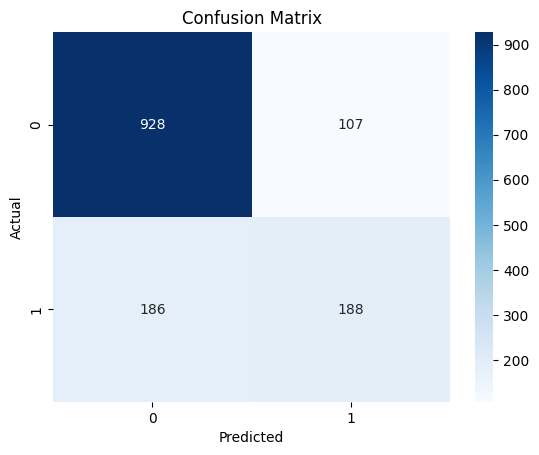

In [11]:
# Step 11: Evaluate the model
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

TotalCharges        0.186841
MonthlyCharges      0.179192
tenure              0.154338
Contract            0.079631
PaymentMethod       0.050095
OnlineSecurity      0.049580
TechSupport         0.043603
gender              0.027892
InternetService     0.027789
OnlineBackup        0.027075
PaperlessBilling    0.025767
MultipleLines       0.023449
Partner             0.022726
DeviceProtection    0.021445
SeniorCitizen       0.021097
Dependents          0.019836
StreamingMovies     0.017632
StreamingTV         0.016804
PhoneService        0.005209
dtype: float64


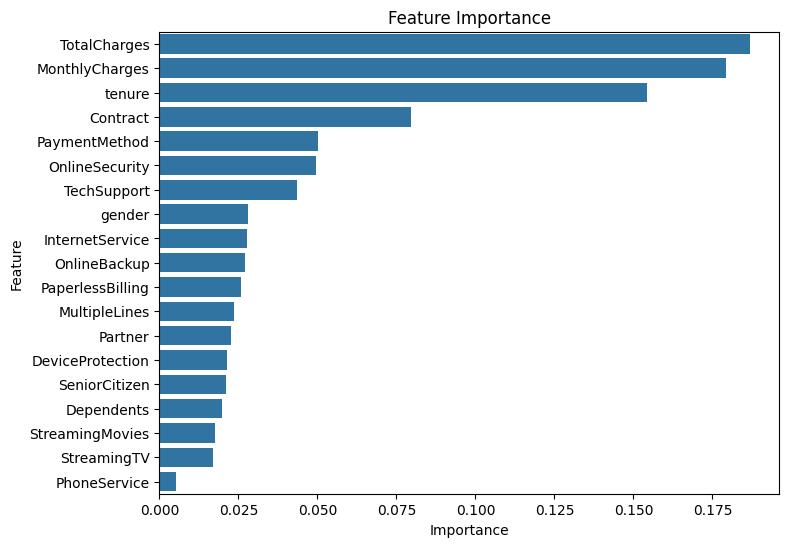

['random_forest_churn_model.pkl']

In [12]:
# Step 12: Explain feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# Bonus: Save the model
joblib.dump(rf, "random_forest_churn_model.pkl")

In [ ]:
# Step 13: Conclusion
# - Dataset: Telco Customer Churn (Kaggle, blastchar), 7,043 rows
# - Model: Random Forest Classifier (100 trees), 80/20 stratified split
# - Preprocessing: converted TotalCharges to numeric, filled missing values
#   with the median, dropped customerID, label-encoded categorical columns
# - Metrics: Accuracy, Precision, Recall, F1-Score, Confusion Matrix
# - Key findings: the most important features (see the importance plot above)
#   are typically TotalCharges, MonthlyCharges, tenure and Contract type
# - Conclusion: Random Forest predicts churn reasonably well, but recall for
#   the churn class is lower because the data is imbalanced. Handling the
#   imbalance (class_weight='balanced' or SMOTE) and hyperparameter tuning
#   could improve results.